<a href="https://colab.research.google.com/github/nicolasrporto/Python/blob/main/AtividadeAvaliativa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<>:126: SyntaxWarning: invalid escape sequence '\p'
<>:238: SyntaxWarning: invalid escape sequence '\s'
<>:254: SyntaxWarning: invalid escape sequence '\l'
<>:126: SyntaxWarning: invalid escape sequence '\p'
<>:238: SyntaxWarning: invalid escape sequence '\s'
<>:254: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_796/3154041440.py:126: SyntaxWarning: invalid escape sequence '\p'
  ax2.set_title("Caso 2: Carga Pontual entre Placas de Capacitor ($V = \pm 1$)")
/tmp/ipykernel_796/3154041440.py:238: SyntaxWarning: invalid escape sequence '\s'
  plt.xlabel('Distância Radial Real $r = \sqrt{(x-x_c)^2 + (y-y_c)^2}$ (m)', fontsize=12)
/tmp/ipykernel_796/3154041440.py:254: SyntaxWarning: invalid escape sequence '\l'
  plt.plot(r_teorico, V_teorico_ajustado, 'k--', linewidth=2, label='Curva Teórica Ajustada $A\ln(1/r) + B$')


Digite o comprimento do lado do quadrado L: 1
Digite a posição x da placa esquerda (V=-1) (Sugestão: 0.33): 0.33
Digite a posição x da placa direita (V=+1) (Sugestão: 0.66): 0.66
Digite a altura vertical 'h' das placas (Sugestão: 0.50): 0.5
Digite o passo espacial dx: 0.05
Digite a tolerância de convergência eps: 0.0001
Digite o número máximo de iterações Nmax: 1000
Digite a coordenada x da carga (ex: 0.5): 0.5
Digite a coordenada y da carga (ex: 0.5): 0.5
Digite o parâmetro de intensidade da carga Q/$eps0$: 1
--> Caso 1 convergiu com 671 iterações. Erro final: 9.906634e-05
--> Caso 2 convergiu com 193 iterações. Erro final: 9.551538e-05


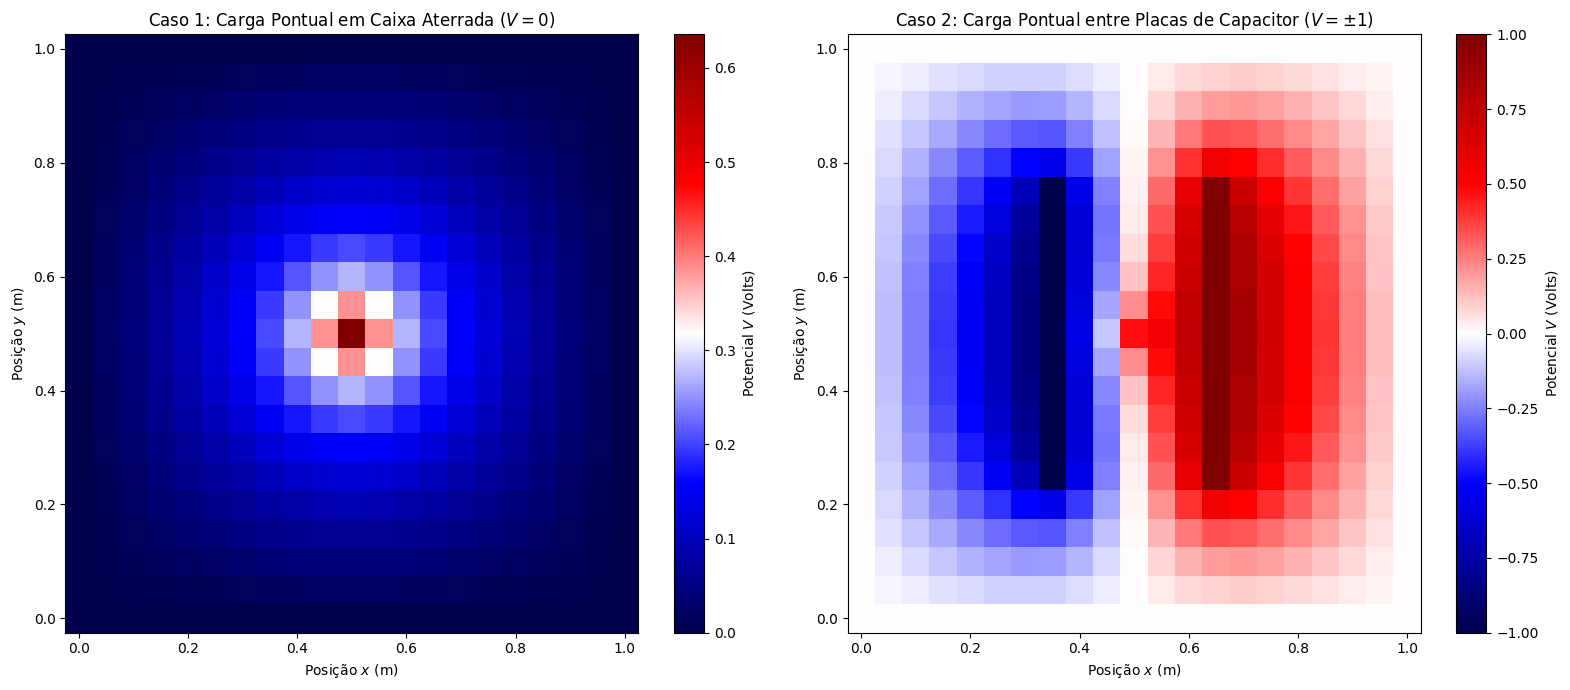

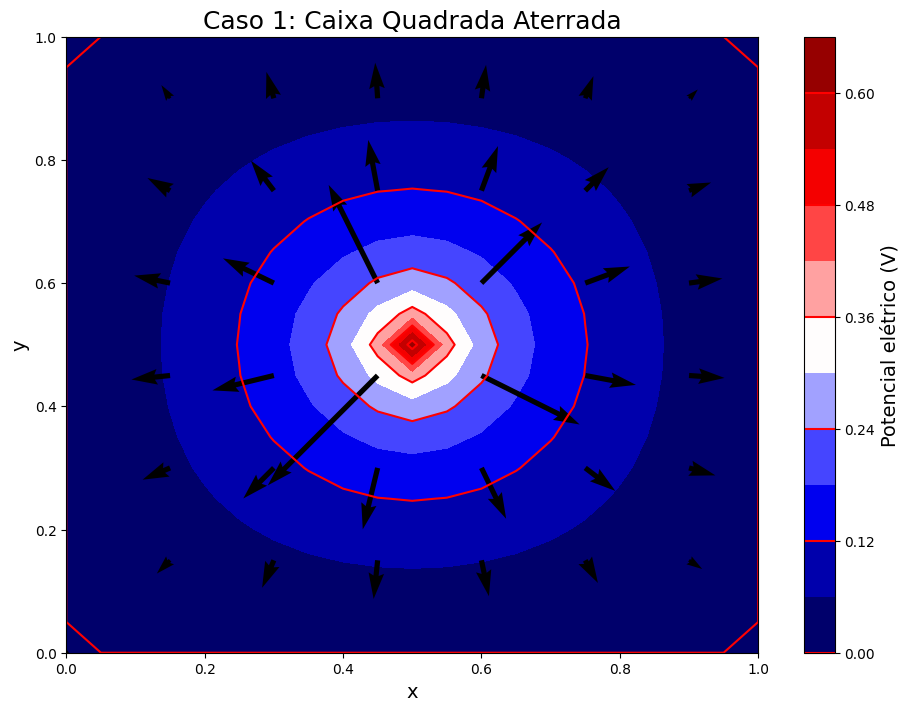

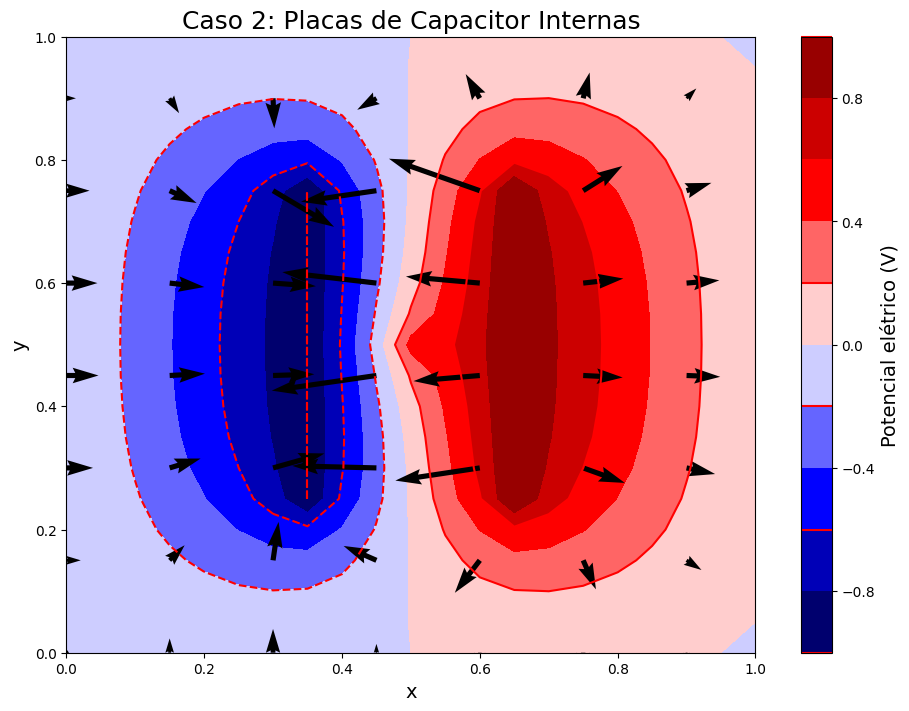

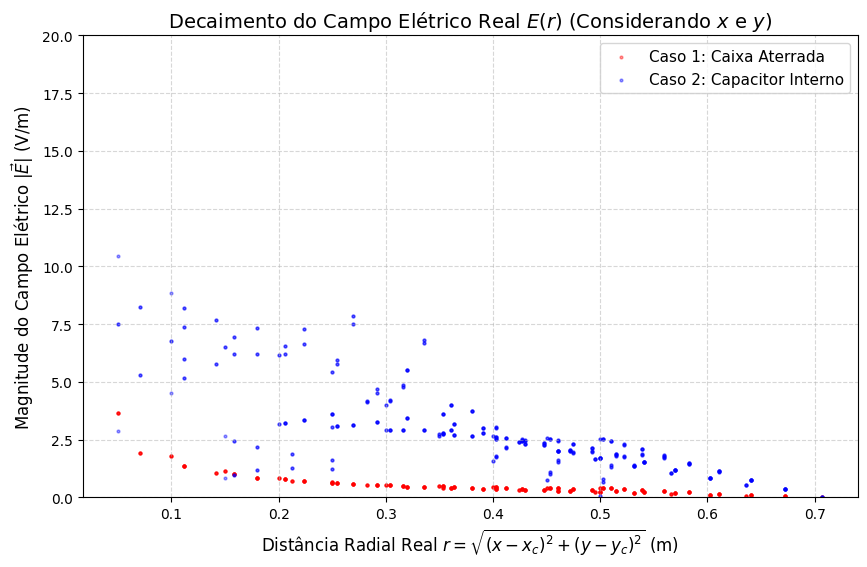

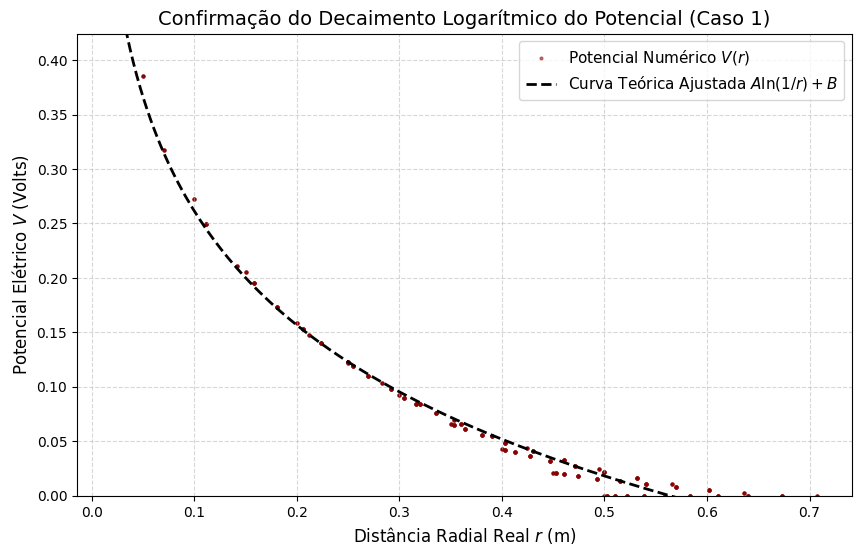

Equação do ajuste: V(r) = 0.1511 * ln(1/r) + (-0.0866)


In [6]:
import numpy as np
import matplotlib.pyplot as plt

#input

L = float(input("Digite o comprimento do lado do quadrado L: "))
while True:
    x1 = float(input(f"Digite a posição x da placa esquerda (V=-1) (Sugestão: {0.33*L:.2f}): "))
    if 0 < x1 < L:
        break
    print(f"Erro: A posição deve estar estritamente entre 0 e {L} metros!")

# 2. Validação da Placa Direita (Deve estar entre x1 e L para não cruzar as placas)
while True:
    x2 = float(input(f"Digite a posição x da placa direita (V=+1) (Sugestão: {0.66*L:.2f}): "))
    if x1 < x2 < L:
        break
    print(f"Erro: A placa direita deve estar após a placa esquerda ({x1}) e dentro do limite {L}!")

# 3. Validação da Altura h (A altura não pode ser maior que o próprio lado L da caixa)
while True:
    h = float(input(f"Digite a altura vertical 'h' das placas (Sugestão: {0.50*L:.2f}): "))
    if 0 < h <= L:
        break
    print(f"Erro: A altura 'h' não pode ser negativa e nem maior que o lado total da caixa ({L})!")
dx = float(input("Digite o passo espacial dx: "))
dy = dx
eps = float(input("Digite a tolerância de convergência eps: "))
Nmax = int(input("Digite o número máximo de iterações Nmax: "))
xc = float(input("Digite a coordenada x da carga (ex: 0.5): "))
yc = float(input("Digite a coordenada y da carga (ex: 0.5): "))
C_parametro = float(input("Digite o parâmetro de intensidade da carga Q/$eps0$: "))


# converter o input da carga para índices de matriz.
ic = round(xc/dx)
jc = round(yc/dy)
ix1 = round(x1 / dx)
ix2 = round(x2 / dx)
iy1 = round((L - h) / (2.0 * dx))
iy2 = round((L + h) / (2.0 * dx))

# Dimensões da matriz baseadas nos EPs já feitos.
xsize = round(L/dx) + 1
ysize = round(L/dy) + 1

#vetores auxiliares com as coordenadas reais de x e y.

x = np.linspace(0, L, xsize)
y = np.linspace(0, L, ysize)

#rô baseado no parâmetro C=Q/eps0 (input, seguindo o PDF)
rho_over_eps0 = np.zeros((xsize, ysize))
rho_over_eps0[ic, jc] = C_parametro /(dx*dy)


def poisson(caso=1):

    V = np.zeros((xsize, ysize))
    V_old = np.zeros((xsize, ysize))

    #seguindo o padrão explicitado na tarefa em sala:

    V[0, :] = 0.0   # Borda esquerda
    V[-1, :] = 0.0  # Borda direita
    V[:, 0] = 0.0   # Borda inferior
    V[:, -1] = 0.0  # Borda superior

    #condição de contorno caso 2
    if caso == 2:
      V[ix1, iy1:iy2 + 1] = -1.0
      V[ix2, iy1:iy2 + 1] = 1.0


    # Copia as condições de contorno iniciais para V_old de forma segura (sem ponteiros)
    V_old[:] = V

    # LAÇO ITERATIVO DE RELAXAÇÃO DE JACOBI

    for iteracao in range(Nmax):

        #atualização pontos internos
        termo_x = (V_old[2:, 1:-1] + V_old[:-2, 1:-1]) * (dy**2)
        termo_y = (V_old[1:-1, 2:] + V_old[1:-1, :-2]) * (dx**2)

        #
        termo_rho = rho_over_eps0[1:-1, 1:-1]*(dx**2)*(dy**2)

        # Atualização simultânea da malha interna
        V[1:-1, 1:-1] = (termo_x + termo_y + termo_rho) / (2.0 * (dx**2 + dy**2))

        # Se for o Caso 2, força o potencial fixo das placas internas a cada iteração
        if caso == 2:
            V[ix1, iy1:iy2 + 1] = -1.0
            V[ix2, iy1:iy2 + 1] = 1.0

        # Critério de convergência
        erro = np.sum(np.abs(V - V_old))

        if erro < eps:
            print(f"--> Caso {caso} convergiu com {iteracao} iterações. Erro final: {erro:.6e}")
            break

        # Atualização da matriz
        V_old[:] = V

    return V

# 3. EXECUÇÃO E PLOT DOS DOIS CENÁRIOS
V_caso1 = poisson(caso=1)
V_caso2 = poisson(caso=2)

# Criando os gráficos comparativos para o Potencial Elétrico
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Plot Caso 1
im1 = ax1.pcolormesh(x, y, np.transpose(V_caso1), cmap='seismic', shading='auto')
fig.colorbar(im1, ax=ax1, label="Potencial $V$ (Volts)")
ax1.set_title("Caso 1: Carga Pontual em Caixa Aterrada ($V=0$)")
ax1.set_xlabel("Posição $x$ (m)")
ax1.set_ylabel("Posição $y$ (m)")

# Plot Caso 2
im2 = ax2.pcolormesh(x, y, np.transpose(V_caso2), cmap='seismic', shading='auto')
fig.colorbar(im2, ax=ax2, label="Potencial $V$ (Volts)")
ax2.set_title("Caso 2: Carga Pontual entre Placas de Capacitor ($V = \pm 1$)")
ax2.set_xlabel("Posição $x$ (m)")
ax2.set_ylabel("Posição $y$ (m)")

plt.tight_layout()
plt.show()


# CÁLCULO DAS COMPONENTES DE CAMPO - CASO 1 (CAIXA ATERRADA)
Ex_caso1 = np.zeros((xsize, ysize))
Ey_caso1 = np.zeros((xsize, ysize))

Ex_caso1[1:-1, 1:-1] = -(V_caso1[2:, 1:-1] - V_caso1[:-2, 1:-1]) / (2.0 * dx)
Ey_caso1[1:-1, 1:-1] = -(V_caso1[1:-1, 2:] - V_caso1[1:-1, :-2]) / (2.0 * dy)

# Tratamento direto das derivadas de contorno (bordas externas)
Ex_caso1[0, :]  = -(V_caso1[1, :] - V_caso1[0, :]) / dx    # Esquerda
Ex_caso1[-1, :] = -(V_caso1[-1, :] - V_caso1[-2, :]) / dx  # Direita
Ey_caso1[:, 0]  = -(V_caso1[:, 1] - V_caso1[:, 0]) / dy    # Inferior
Ey_caso1[:, -1] = -(V_caso1[:, -1] - V_caso1[:, -2]) / dy  # Superior

# Magnitude total do campo para o Caso 1 (Pitágoras instantâneo)
E_modulo_caso1 = np.sqrt(Ex_caso1**2 + Ey_caso1**2)


# CÁLCULO DAS COMPONENTES DE CAMPO - CASO 2 (CAPACITOR INTERNO)
Ex_caso2 = np.zeros((xsize, ysize))
Ey_caso2 = np.zeros((xsize, ysize))

#aproximação da primeira derivada (exceto bordas)
Ex_caso2[1:-1, 1:-1] = -(V_caso2[2:, 1:-1] - V_caso2[:-2, 1:-1]) / (2.0 * dx)
Ey_caso2[1:-1, 1:-1] = -(V_caso2[1:-1, 2:] - V_caso2[1:-1, :-2]) / (2.0 * dy)

#aproximação da primeira derivada(bordas externas)
Ex_caso2[0, :]  = -(V_caso2[1, :] - V_caso2[0, :]) / dx    # Esquerda
Ex_caso2[-1, :] = -(V_caso2[-1, :] - V_caso2[-2, :]) / dx  # Direita
Ey_caso2[:, 0]  = -(V_caso2[:, 1] - V_caso2[:, 0]) / dy    # Inferior
Ey_caso2[:, -1] = -(V_caso2[:, -1] - V_caso2[:, -2]) / dy  # Superior

#módulo do campo elétrico
E_modulo_caso2 = np.sqrt(Ex_caso2**2 + Ey_caso2**2)

#Plots Campos Elétricos

origin = 'lower'
p = 3

# GRAFICO - CASO 1: Caixa Quadrada Aterrada

fig1, ax2 = plt.subplots(constrained_layout=True, figsize=(9, 7))

CS = ax2.contourf(x, y, np.transpose(V_caso1), 10, origin=origin, cmap='seismic')

CS2 = ax2.contour(CS, levels=CS.levels[::2], colors='r', origin=origin)

#função quiver que plota o campo vetorial puramente numérico (Ex_caso1, Ey_caso1)
CS3 = ax2.quiver(x[::p], y[::p], Ex_caso1.T[::p, ::p], Ey_caso1.T[::p, ::p])

ax2.set_title('Caso 1: Caixa Quadrada Aterrada', fontsize='18')
ax2.set_xlabel('x', fontsize='14')
ax2.set_ylabel('y', fontsize='14')

# Barra de cores lateral integrada com as linhas vermelhas
cbar = fig1.colorbar(CS)
cbar.ax.set_ylabel('Potencial elétrico (V)', fontsize='14')
cbar.add_lines(CS2)
plt.show()

# GRAFICO - CASO 2: Placas de Capacitor Internas
fig2, ax3 = plt.subplots(constrained_layout=True, figsize=(9, 7))

CS_c2 = ax3.contourf(x, y, np.transpose(V_caso2), 10, origin=origin, cmap='seismic')

CS2_c2 = ax3.contour(CS_c2, levels=CS_c2.levels[::2], colors='r', origin=origin)

#função quiver que plota o campo vetorial puramente numérico (Ex_caso2, Ey_caso2)
CS3_c2 = ax3.quiver(x[::p], y[::p], Ex_caso2.T[::p, ::p], Ey_caso2.T[::p, ::p])

ax3.set_title('Caso 2: Placas de Capacitor Internas', fontsize='18')
ax3.set_xlabel('x', fontsize='14')
ax3.set_ylabel('y', fontsize='14')

cbar_c2 = fig2.colorbar(CS_c2)
cbar_c2.ax.set_ylabel('Potencial elétrico (V)', fontsize='14')
cbar_c2.add_lines(CS2_c2)
plt.show()

#gráfico E(r) x r para os dois casos

X_mesh, Y_mesh = np.meshgrid(x, y, indexing='ij')

Distancia_Real = np.sqrt((X_mesh - xc)**2 + (Y_mesh - yc)**2)

raio_todos_pontos = Distancia_Real.flatten()
E1_todos_pontos = E_modulo_caso1.flatten()
E2_todos_pontos = E_modulo_caso2.flatten()

mascara = raio_todos_pontos > 0.02
raio_plot = raio_todos_pontos[mascara]
E1_plot = E1_todos_pontos[mascara]
E2_plot = E2_todos_pontos[mascara]

V1_todos_pontos = V_caso1.flatten()
V1_plot = V1_todos_pontos[mascara]

plt.figure(figsize=(10, 6))

# Usou-se scatter porque existem vários pontos diferentes no plano com a mesma distância r
plt.scatter(raio_plot, E1_plot, color='red', alpha=0.4, s=4, label='Caso 1: Caixa Aterrada')
plt.scatter(raio_plot, E2_plot, color='blue', alpha=0.4, s=4, label='Caso 2: Capacitor Interno')

plt.title('Decaimento do Campo Elétrico Real $E(r)$ (Considerando $x$ e $y$)', fontsize=14)
plt.xlabel('Distância Radial Real $r = \sqrt{(x-x_c)^2 + (y-y_c)^2}$ (m)', fontsize=12)
plt.ylabel('Magnitude do Campo Elétrico $|\\vec{E}|$ (V/m)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.ylim(0, 20)

plt.show()

A, B = np.polyfit(np.log(1.0 / raio_plot), V1_plot, 1)

plt.figure(figsize=(10, 6))

plt.scatter(raio_plot, V1_plot, color='darkred', s=4, alpha=0.5, label='Potencial Numérico $V(r)$')

r_teorico = np.linspace(0.02, 0.7, 200)
V_teorico_ajustado = A * np.log(1.0 / r_teorico) + B
plt.plot(r_teorico, V_teorico_ajustado, 'k--', linewidth=2, label='Curva Teórica Ajustada $A\ln(1/r) + B$')

plt.title('Confirmação do Decaimento Logarítmico do Potencial (Caso 1)', fontsize=14)
plt.xlabel('Distância Radial Real $r$ (m)', fontsize=12)
plt.ylabel('Potencial Elétrico $V$ (Volts)', fontsize=12)

plt.ylim(0, np.max(V1_plot) * 1.1)

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.show()

print(f"Equação do ajuste: V(r) = {A:.4f} * ln(1/r) + ({B:.4f})")

Digite o raio da espira R em metros: 1
Digite a corrente elétrica I em Amperes: 1
Digite o número de divisões da espira N_theta: 1000


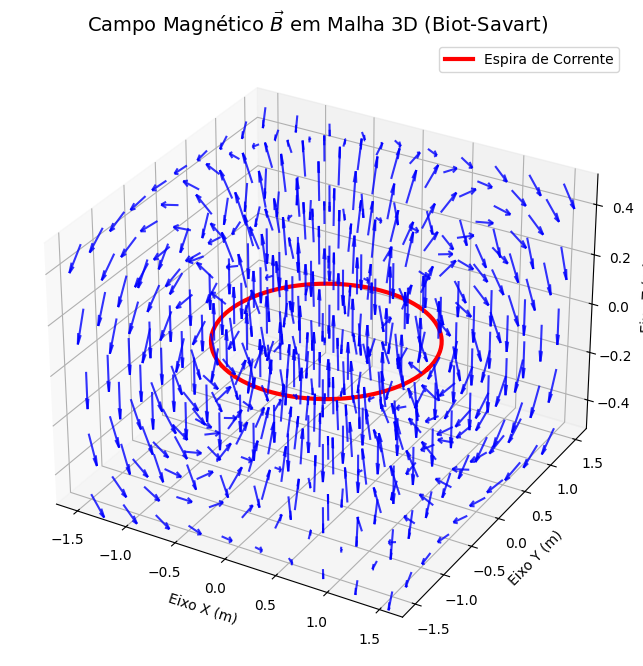

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

#inputs

R = float(input("Digite o raio da espira R em metros: "))
#para variar o mi0*I para além de 1, colocarei a corrente como input.
I = float(input("Digite a corrente elétrica I em Amperes: "))
N_theta = int(input("Digite o número de divisões da espira N_theta: "))

#para a construção do gráfico e o processamento fiz um grid de pontos fixados pelos seguintes valores (tentei utilizá-los como input, mas o gráfico ficou muito poluído)
Nx, Ny, Nz = 10, 10, 5
x = np.linspace(-1.5*R, 1.5*R, Nx)
y = np.linspace(-1.5*R, 1.5*R, Ny)
#z não pode ser muito grande (como explicitado no PDF)
z = np.linspace(-0.5*R, 0.5*R, Nz)


# N_theta tem que ser ímpar para que o número de divisões seja par e a regra 1/3 de simpson funcione
if N_theta % 2 == 0:
    N_theta += 1

#para o gráfico
X, Y, Z = np.meshgrid(x, y, z, indexing='ij')

# Matrizes tridimensionais para armazenar os componentes do campo magnético (com o mesmo tamanho de X)
Bx = np.zeros_like(X)
By = np.zeros_like(X)
Bz = np.zeros_like(X)

# Constantes
mu0 = 4.0 * np.pi * 1e-7
fator_constante = (mu0 * I) / (4.0 * np.pi)

# Discretização angular da espira
theta = np.linspace(0, 2 * np.pi, N_theta)
d_theta = theta[1] - theta[0]
cos_t = np.cos(theta)
sin_t = np.sin(theta)

#Integração numérica para Biot-Savart

for i in range(Nx):
    for j in range(Ny):
        for k in range(Nz):
            x_ponto = X[i, j, k]
            y_ponto = Y[i, j, k]
            z_ponto = Z[i, j, k]

            # Vetor distância d = r - r' (volta pras cartesianas)
            dx_val = x_ponto - R * cos_t
            dy_val = y_ponto - R * sin_t
            dz_val = z_ponto

            # 1e-9 adicionado aqui dentro da raiz para evitar que o código quebre quando a malha passar exatamente em cima do fio da espira
            dist_cubo = (dx_val**2 + dy_val**2 + dz_val**2 + 1e-9)**(1.5)

            # Componentes do produto vetorial dl x d
            num_x = dz_val * R * cos_t
            num_y = dz_val * R * sin_t
            num_z = R**2 - R * x_ponto * cos_t - R * y_ponto * sin_t

            # Dentro do loop for i, j, k da espira:
            fx = num_x / dist_cubo
            fy = num_y / dist_cubo
            fz = num_z / dist_cubo

            # Integração por Simpson 1/3 direta
            Bx[i, j, k] = fator_constante * (d_theta / 3.0) * (fx[0] + fx[-1] + 4 * np.sum(fx[1:-1:2]) + 2 * np.sum(fx[2:-1:2]))
            By[i, j, k] = fator_constante * (d_theta / 3.0) * (fy[0] + fy[-1] + 4 * np.sum(fy[1:-1:2]) + 2 * np.sum(fy[2:-1:2]))
            Bz[i, j, k] = fator_constante * (d_theta / 3.0) * (fz[0] + fz[-1] + 4 * np.sum(fz[1:-1:2]) + 2 * np.sum(fz[2:-1:2]))


#plot quiver 3d

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

B_norm = np.sqrt(Bx**2 + By**2 + Bz**2)
B_norm = np.where(B_norm == 0, 1e-15, B_norm)

ax.quiver(X, Y, Z, Bx/B_norm, By/B_norm, Bz/B_norm, length=0.15, color='blue', alpha=0.8)

theta_circ = np.linspace(0, 2*np.pi, 100)
ax.plot(R*np.cos(theta_circ), R*np.sin(theta_circ), 0, color='red', linewidth=3, label='Espira de Corrente')

ax.set_title("Campo Magnético $\\vec{B}$ em Malha 3D (Biot-Savart)", fontsize=14)
ax.set_xlabel("Eixo X (m)")
ax.set_ylabel("Eixo Y (m)")
ax.set_zlabel("Eixo Z (m)")
ax.legend()

plt.show()